# EDA

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import warnings
warnings.filterwarnings('ignore')

In [6]:
df = pd.read_csv('loan_detection.csv')
df

,age,campaign,pdays,previous,no_previous_contact,not_working,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success,Loan_Status_label
0,56,1,999,0,1,0,0,0,0,1,...,0,0,1,0,0,0,0,1,0,0
1,57,1,999,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
2,37,1,999,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
3,40,1,999,0,1,0,1,0,0,0,...,0,0,1,0,0,0,0,1,0,0
4,56,1,999,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,1,999,0,1,1,0,0,0,0,...,0,1,0,0,0,0,0,1,0,1
41184,46,1,999,0,1,0,0,1,0,0,...,0,1,0,0,0,0,0,1,0,0
41185,56,2,999,0,1,1,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
41186,44,1,999,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,1


In [8]:
df.shape

(41188, 60)

In [10]:
df.columns

Index(['age', 'campaign', 'pdays', 'previous', 'no_previous_contact',
       'not_working', 'job_admin.', 'job_blue-collar', 'job_entrepreneur',
       'job_housemaid', 'job_management', 'job_retired', 'job_self-employed',
       'job_services', 'job_student', 'job_technician', 'job_unemployed',
       'job_unknown', 'marital_divorced', 'marital_married', 'marital_single',
       'marital_unknown', 'education_basic.4y', 'education_basic.6y',
       'education_basic.9y', 'education_high.school', 'education_illiterate',
       'education_professional.course', 'education_university.degree',
       'education_unknown', 'default_no', 'default_unknown', 'default_yes',
       'housing_no', 'housing_unknown', 'housing_yes', 'loan_no',
       'loan_unknown', 'loan_yes', 'contact_cellular', 'contact_telephone',
       'month_apr', 'month_aug', 'month_dec', 'month_jul', 'month_jun',
       'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep',
       'day_of_week_fri', 'day_of_week_mon'

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 60 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   age                            41188 non-null  int64
 1   campaign                       41188 non-null  int64
 2   pdays                          41188 non-null  int64
 3   previous                       41188 non-null  int64
 4   no_previous_contact            41188 non-null  int64
 5   not_working                    41188 non-null  int64
 6   job_admin.                     41188 non-null  int64
 7   job_blue-collar                41188 non-null  int64
 8   job_entrepreneur               41188 non-null  int64
 9   job_housemaid                  41188 non-null  int64
 10  job_management                 41188 non-null  int64
 11  job_retired                    41188 non-null  int64
 12  job_self-employed              41188 non-null  int64
 13  job_services    

In [14]:
df.describe()

,age,campaign,pdays,previous,no_previous_contact,not_working,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success,Loan_Status_label
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,...,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,2.567593,962.475454,0.172963,0.963217,0.087623,0.253035,0.224677,0.035350,0.025736,...,0.013839,0.190031,0.206711,0.209357,0.196416,0.197485,0.103234,0.863431,0.033335,0.112654
std,10.42125,2.770014,186.910907,0.494901,0.188230,0.282749,0.434756,0.417375,0.184665,0.158348,...,0.116824,0.392330,0.404951,0.406855,0.397292,0.398106,0.304268,0.343396,0.179512,0.316173
min,17.00000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,32.00000,1.000000,999.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,38.00000,2.000000,999.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
75%,47.00000,3.000000,999.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
max,98.00000,56.000000,999.000000,7.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


# Imbalance Data

In [16]:
df['Loan_Status_label']

0        0
1        0
2        0
3        0
4        0
        ..
41183    1
41184    0
41185    0
41186    1
41187    0
Name: Loan_Status_label, Length: 41188, dtype: int64

In [18]:
df['Loan_Status_label'].value_counts()

Loan_Status_label
0    36548
1     4640
Name: count, dtype: int64

In [20]:
print(round(len(df[df['Loan_Status_label'] == 0])/len(df), 2))
print(round(len(df[df['Loan_Status_label'] == 1])/len(df), 2))

0.89
0.11


# Missing Data

In [22]:
df.isnull().sum()

age                              0
campaign                         0
pdays                            0
previous                         0
no_previous_contact              0
not_working                      0
job_admin.                       0
job_blue-collar                  0
job_entrepreneur                 0
job_housemaid                    0
job_management                   0
job_retired                      0
job_self-employed                0
job_services                     0
job_student                      0
job_technician                   0
job_unemployed                   0
job_unknown                      0
marital_divorced                 0
marital_married                  0
marital_single                   0
marital_unknown                  0
education_basic.4y               0
education_basic.6y               0
education_basic.9y               0
education_high.school            0
education_illiterate             0
education_professional.course    0
education_university

# Duplicate Data

In [24]:
df.duplicated().sum()

2417

In [26]:
df[df.duplicated()]

,age,campaign,pdays,previous,no_previous_contact,not_working,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success,Loan_Status_label
10,41,1,999,0,1,0,0,1,0,0,...,0,0,1,0,0,0,0,1,0,0
11,25,1,999,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
16,35,1,999,0,1,0,0,1,0,0,...,0,0,1,0,0,0,0,1,0,0
31,59,1,999,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
104,52,1,999,0,1,0,1,0,0,0,...,0,0,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40928,21,1,999,0,1,1,0,0,0,0,...,0,0,0,0,1,0,0,1,0,1
41131,58,1,999,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0
41167,32,3,999,0,1,0,1,0,0,0,...,0,0,0,0,0,1,0,1,0,0
41172,31,1,999,0,1,0,1,0,0,0,...,0,0,0,1,0,0,0,1,0,1


In [28]:
df.drop_duplicates(keep='first', inplace=True)

In [30]:
df[df.duplicated()]

,age,campaign,pdays,previous,no_previous_contact,not_working,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success,Loan_Status_label


In [32]:
df.shape

(38771, 60)

In [34]:
df['Loan_Status_label'].value_counts()

Loan_Status_label
0    34179
1     4592
Name: count, dtype: int64

In [36]:
print(round(len(df[df['Loan_Status_label'] == 0])/len(df), 2))
print(round(len(df[df['Loan_Status_label'] == 1])/len(df), 2))

0.88
0.12


# Outliers or Anomalies

------------------age------------------



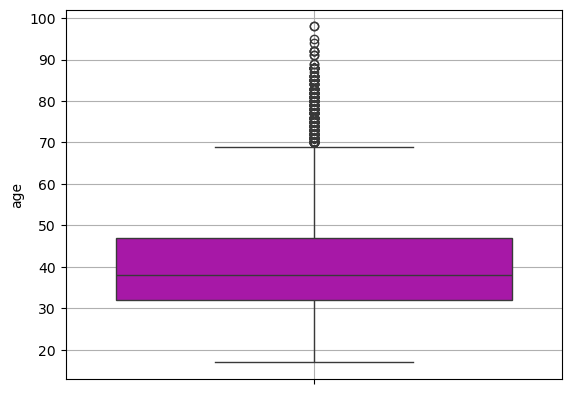

------------------campaign------------------



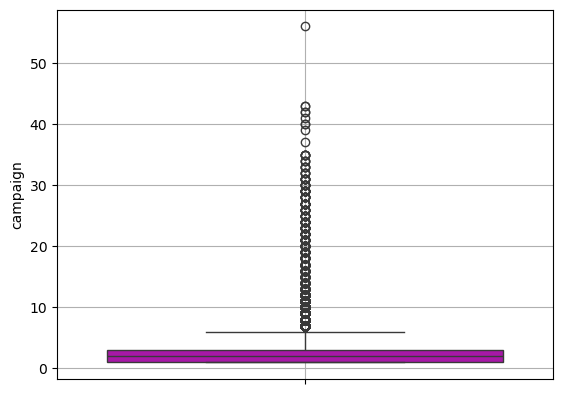

------------------pdays------------------



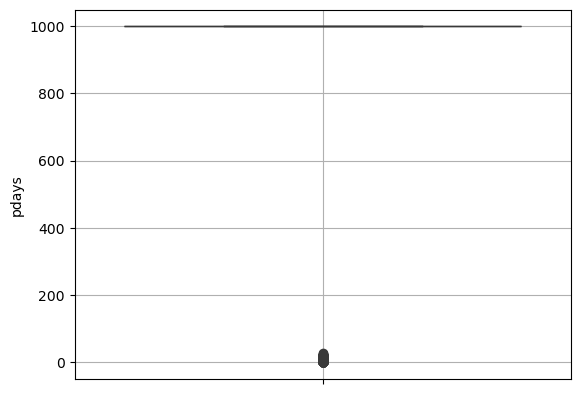

------------------previous------------------



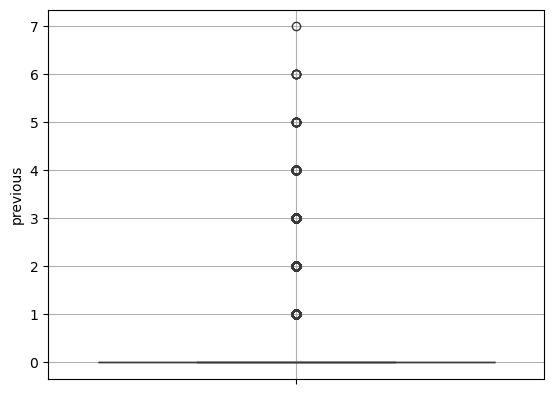

------------------no_previous_contact------------------



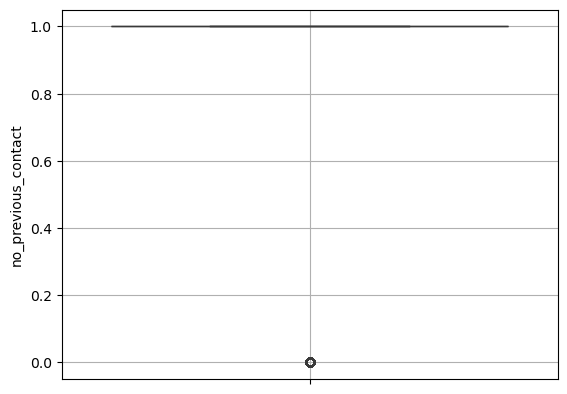

------------------not_working------------------



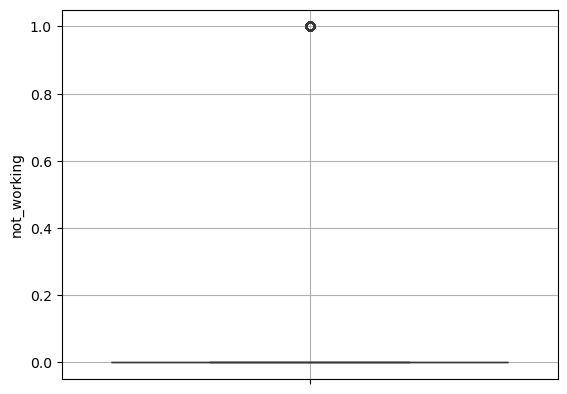

------------------job_admin.------------------



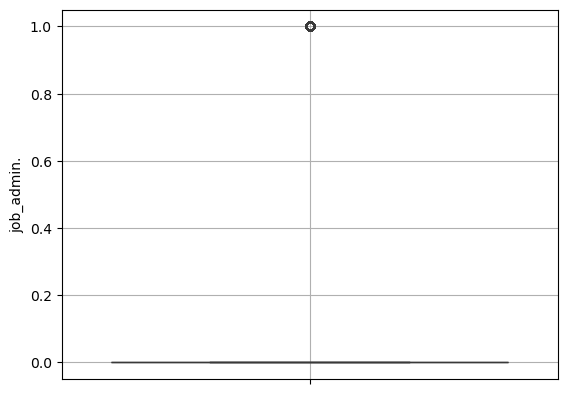

------------------job_blue-collar------------------



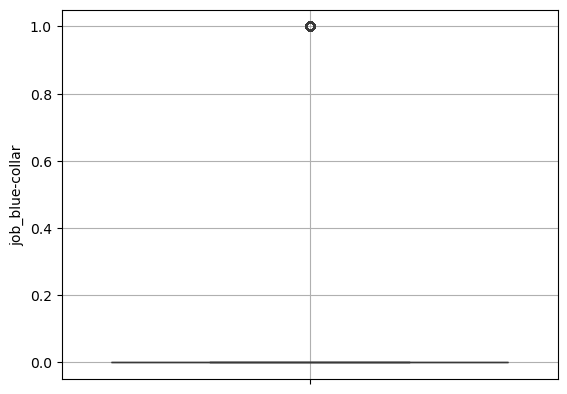

------------------job_entrepreneur------------------



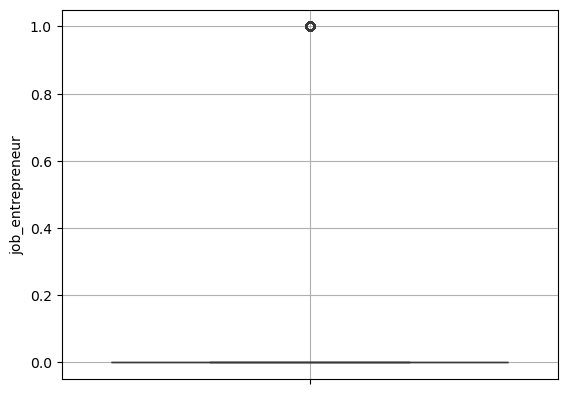

------------------job_housemaid------------------



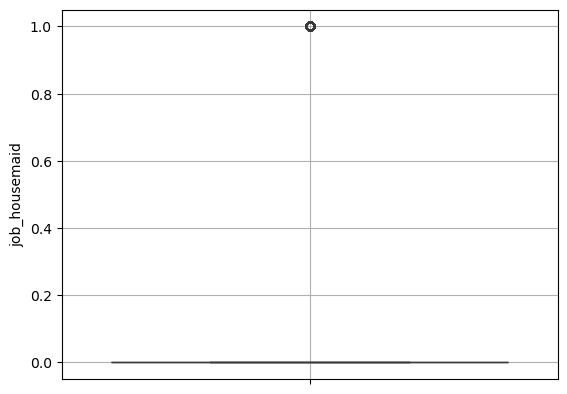

------------------job_management------------------



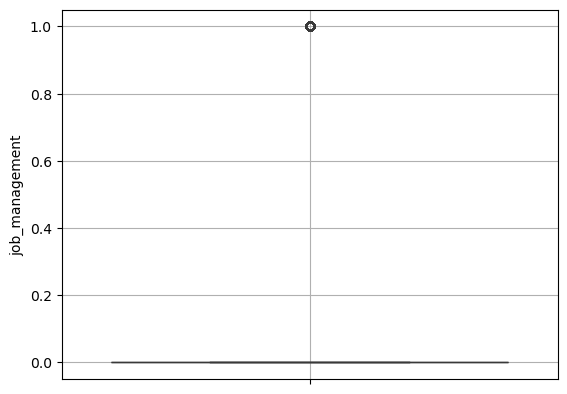

------------------job_retired------------------



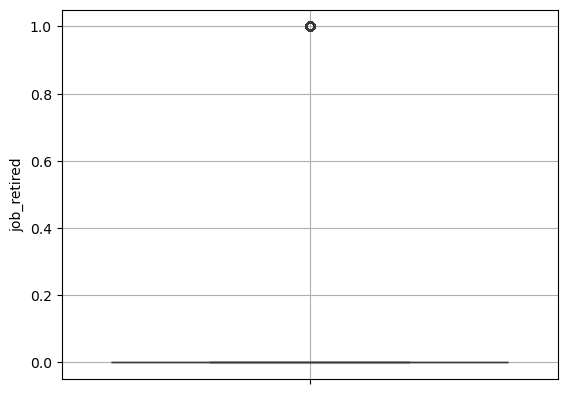

------------------job_self-employed------------------



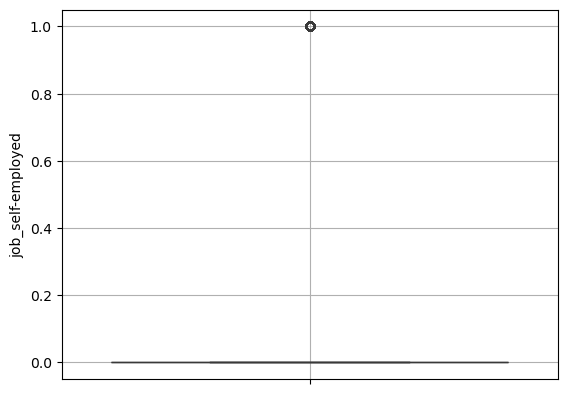

------------------job_services------------------



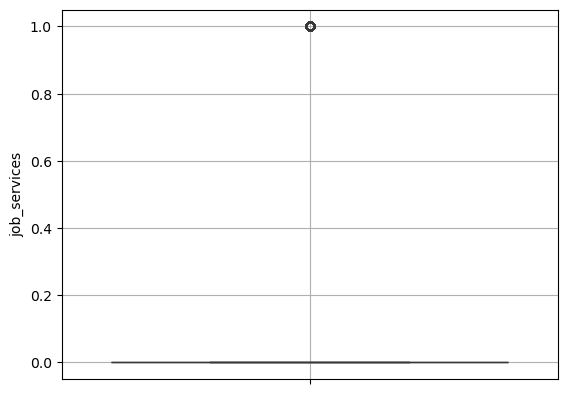

------------------job_student------------------



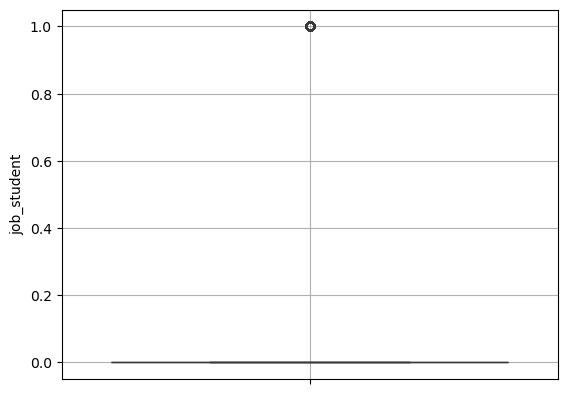

------------------job_technician------------------



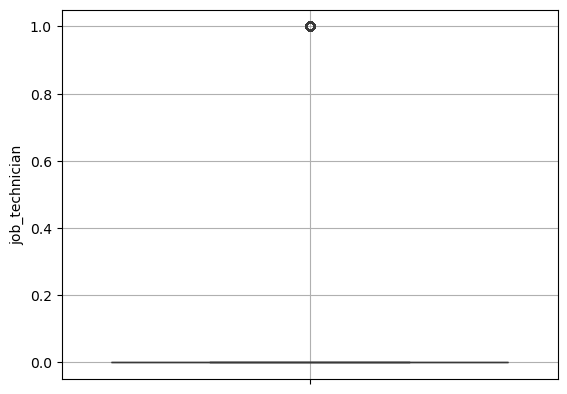

------------------job_unemployed------------------



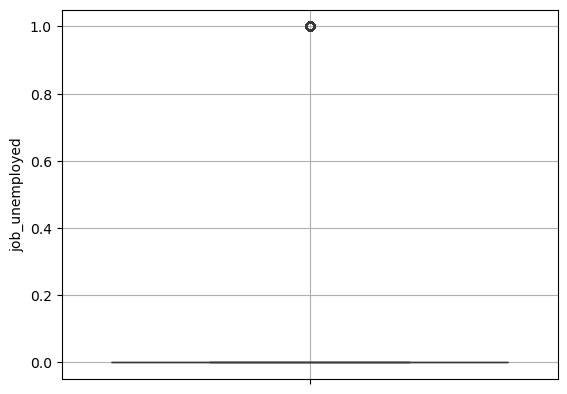

------------------job_unknown------------------



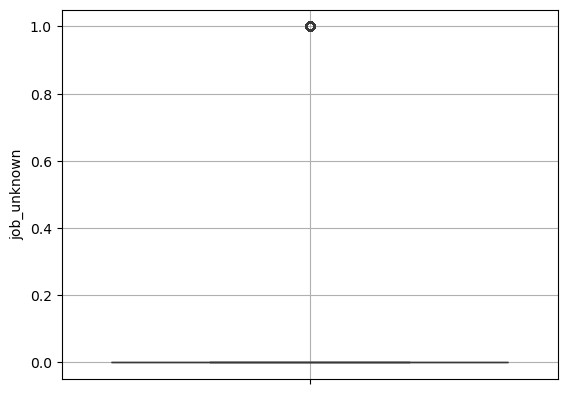

------------------marital_divorced------------------



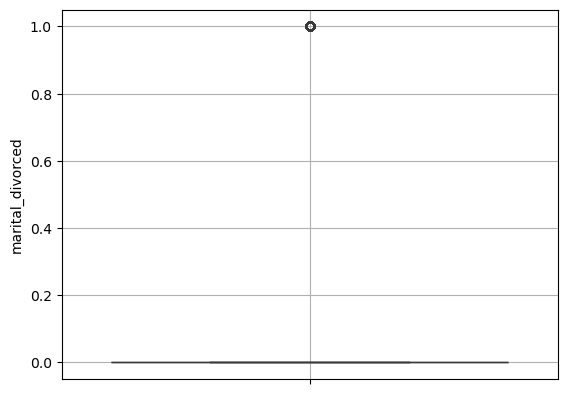

------------------marital_married------------------



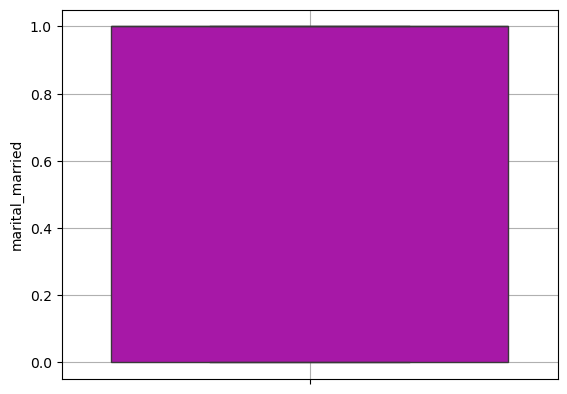

------------------marital_single------------------



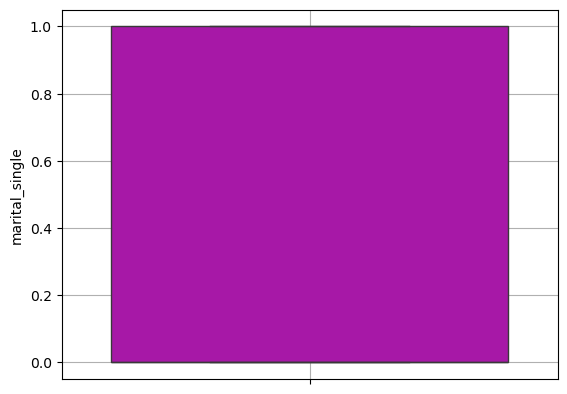

------------------marital_unknown------------------



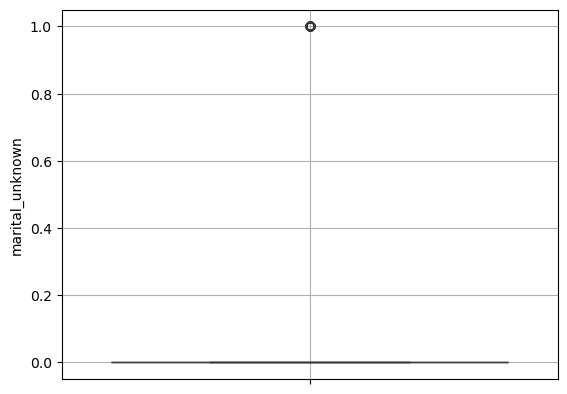

------------------education_basic.4y------------------



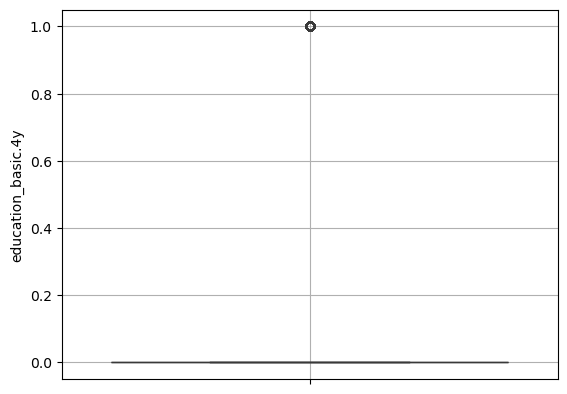

------------------education_basic.6y------------------



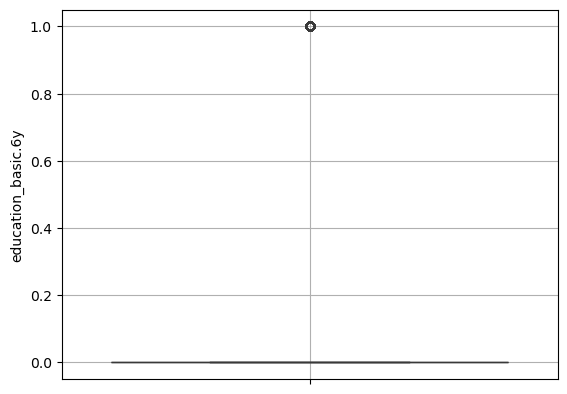

------------------education_basic.9y------------------



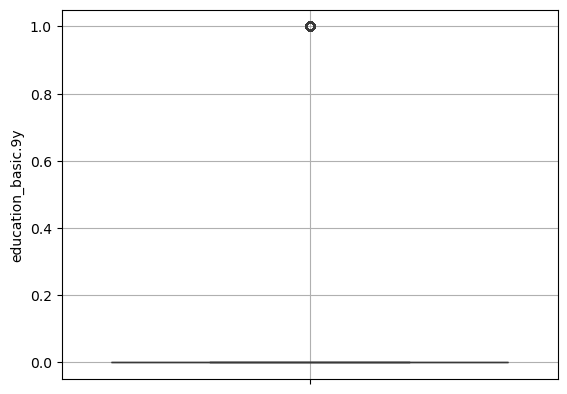

------------------education_high.school------------------



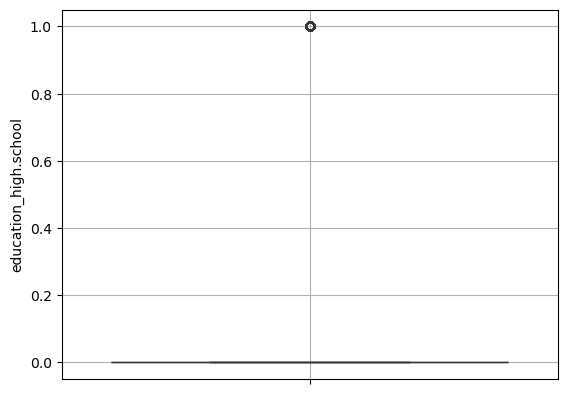

------------------education_illiterate------------------



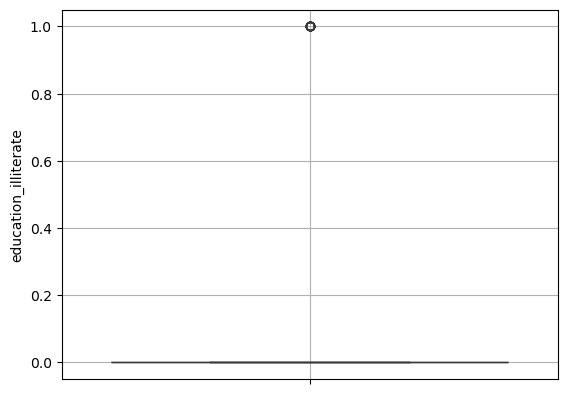

------------------education_professional.course------------------



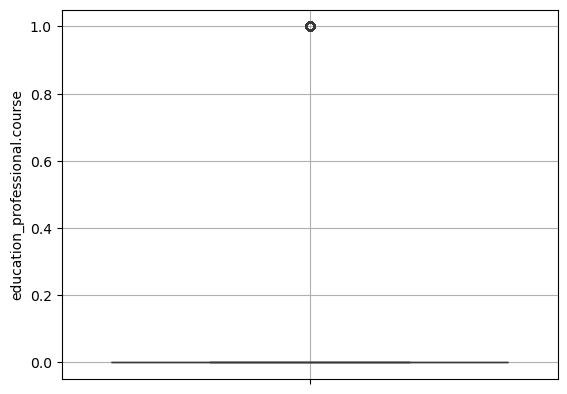

------------------education_university.degree------------------



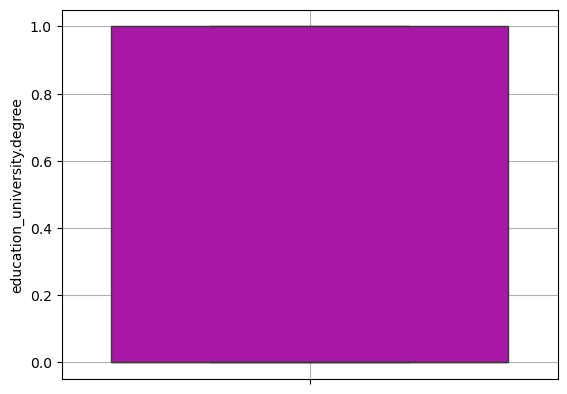

------------------education_unknown------------------



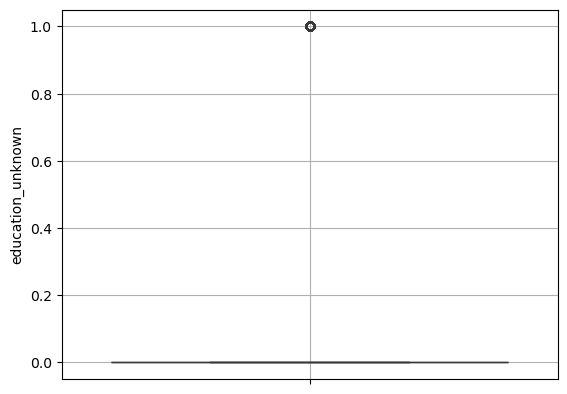

------------------default_no------------------



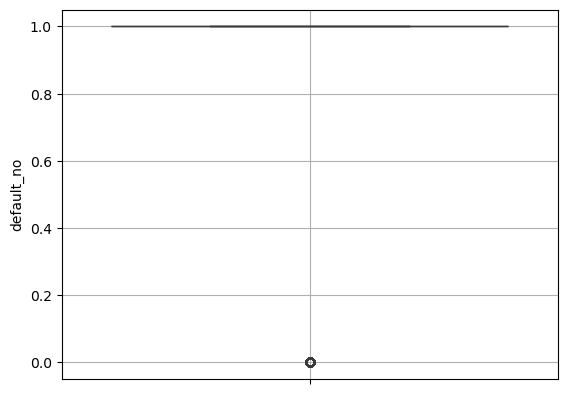

------------------default_unknown------------------



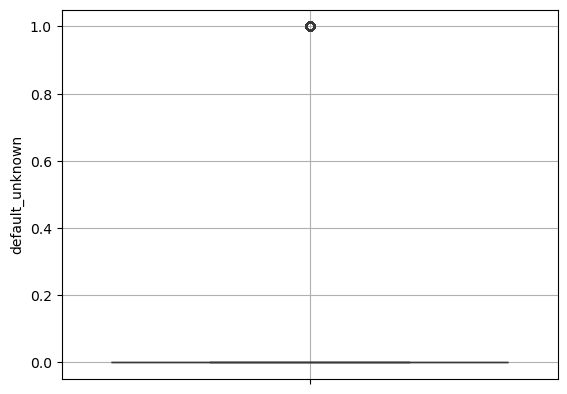

------------------default_yes------------------



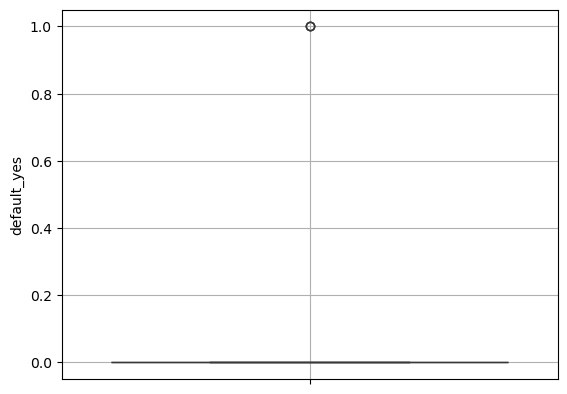

------------------housing_no------------------



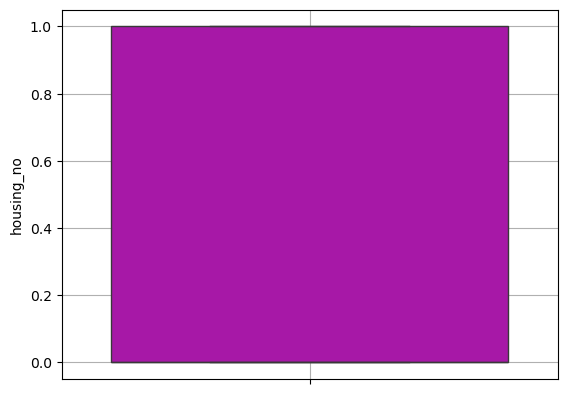

------------------housing_unknown------------------



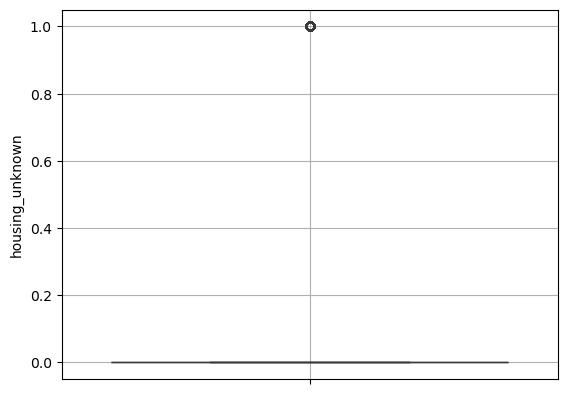

------------------housing_yes------------------



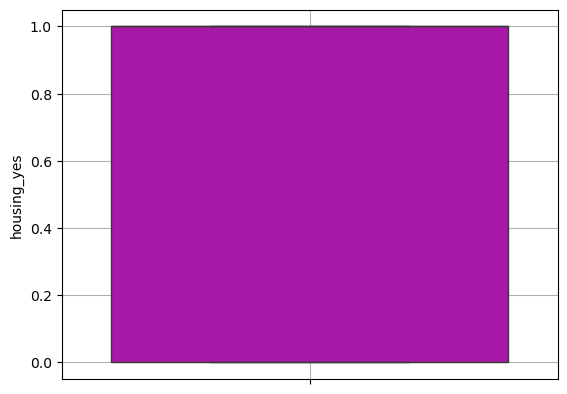

------------------loan_no------------------



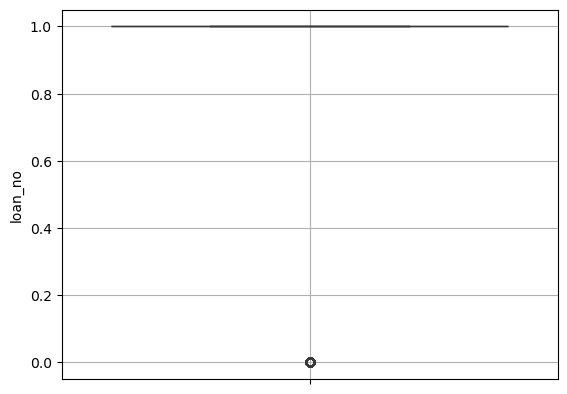

------------------loan_unknown------------------



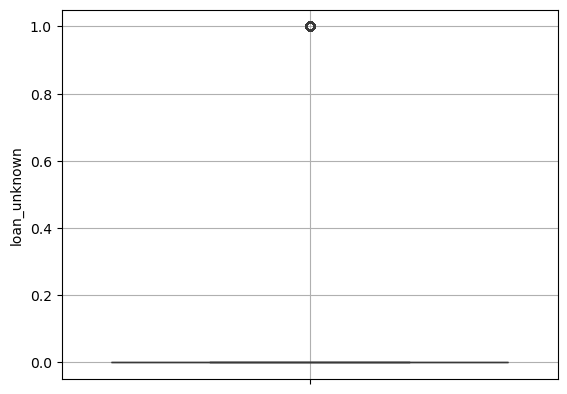

------------------loan_yes------------------



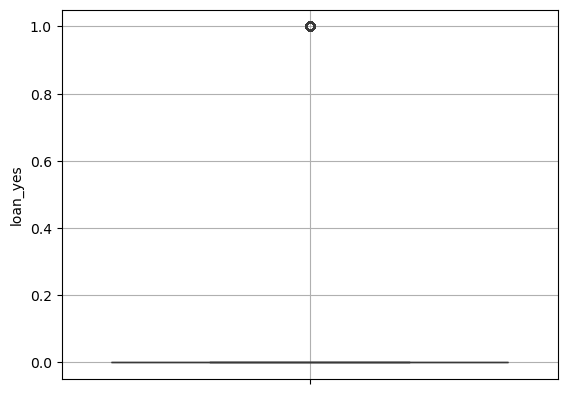

------------------contact_cellular------------------



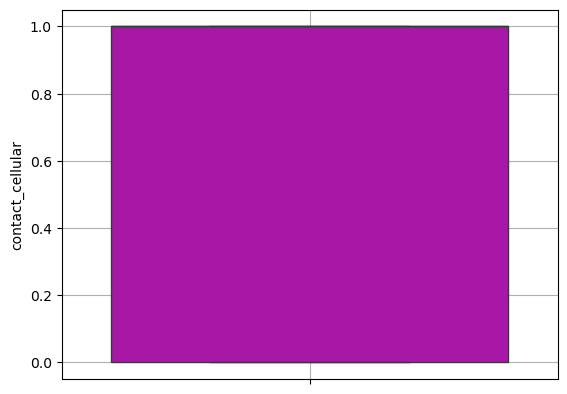

------------------contact_telephone------------------



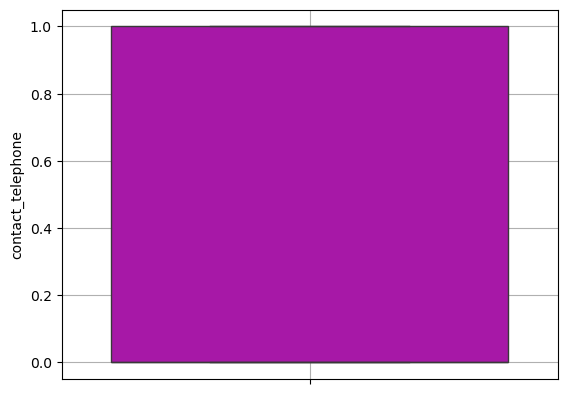

------------------month_apr------------------



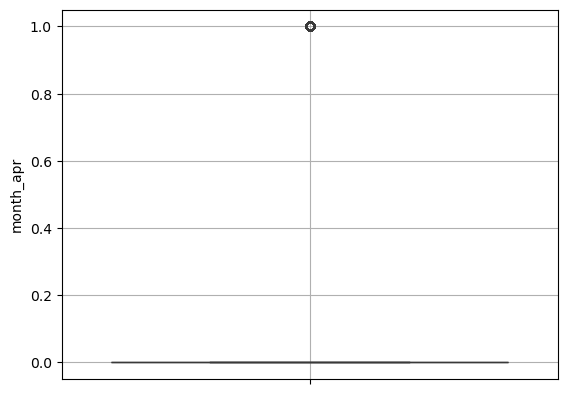

------------------month_aug------------------



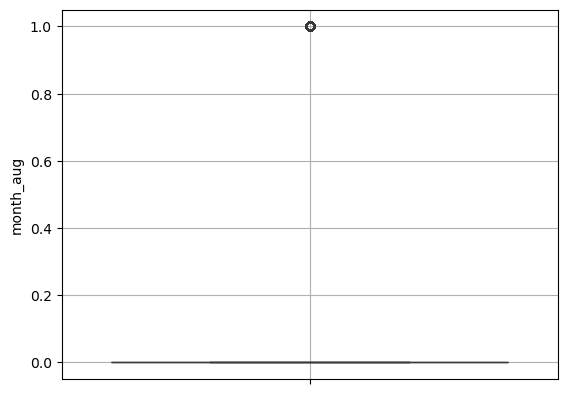

------------------month_dec------------------



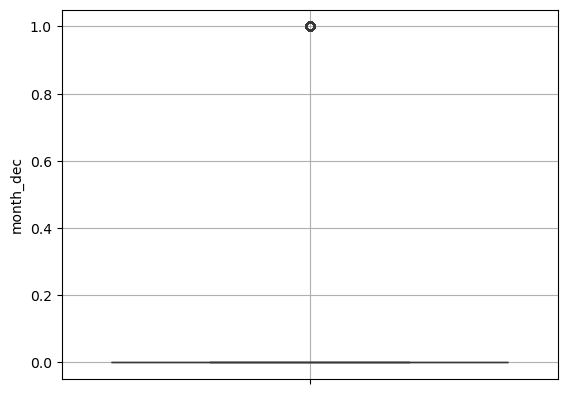

------------------month_jul------------------



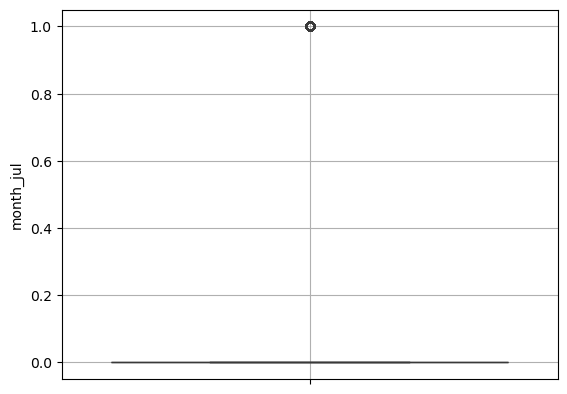

------------------month_jun------------------



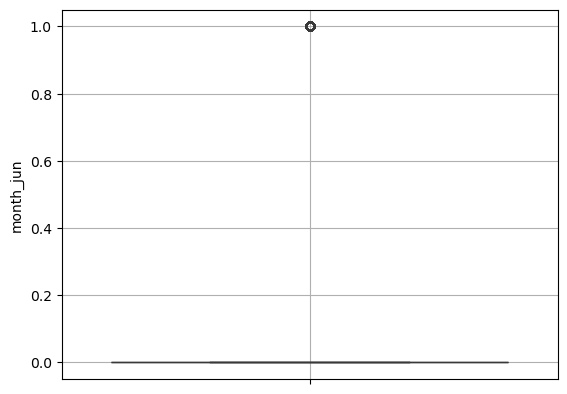

------------------month_mar------------------



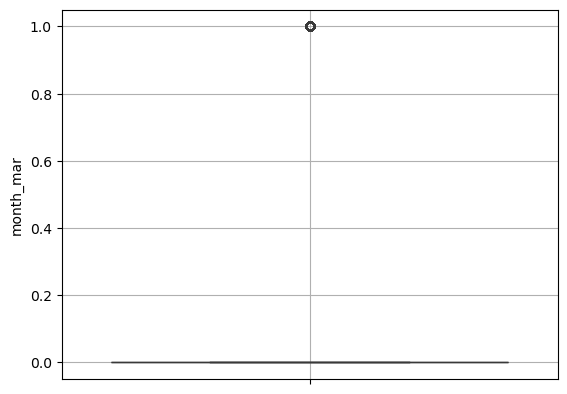

------------------month_may------------------



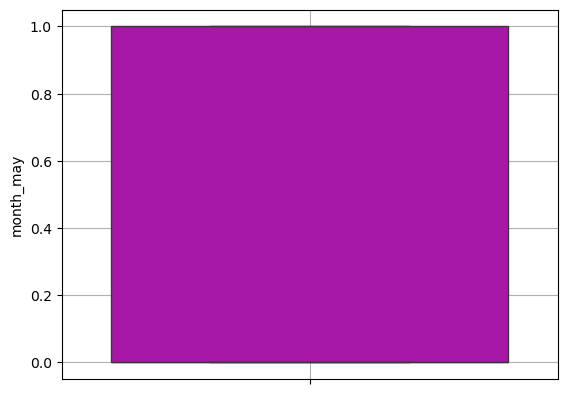

------------------month_nov------------------



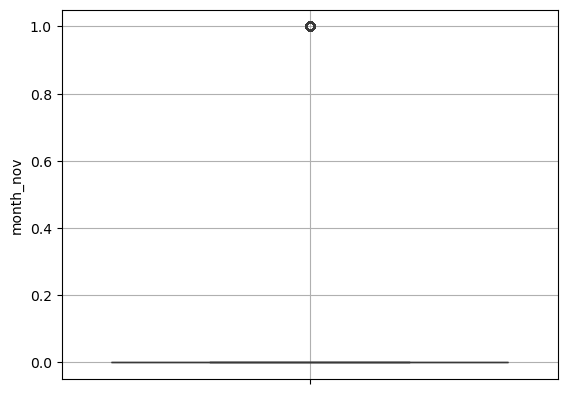

------------------month_oct------------------



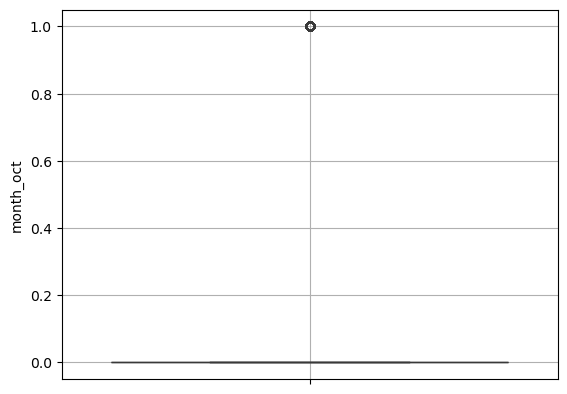

------------------month_sep------------------



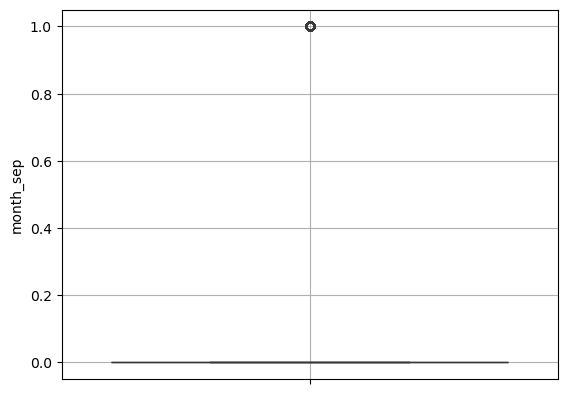

------------------day_of_week_fri------------------



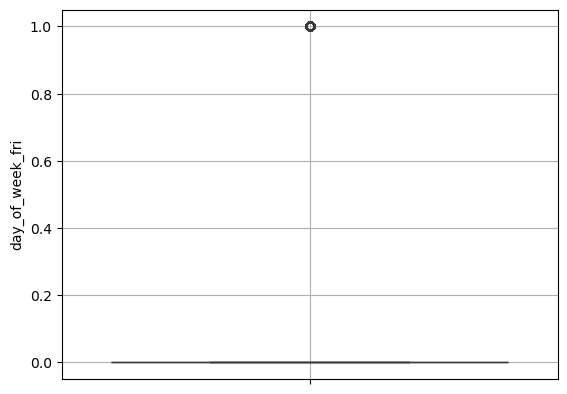

------------------day_of_week_mon------------------



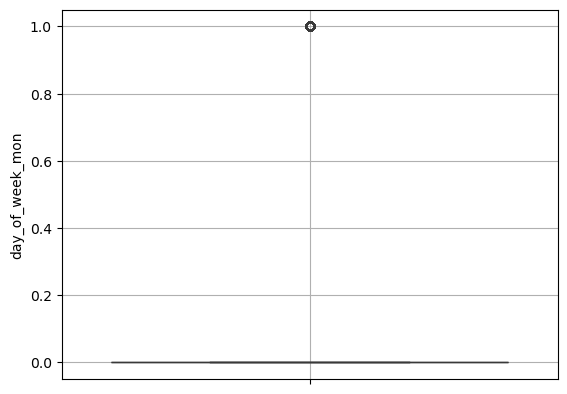

------------------day_of_week_thu------------------



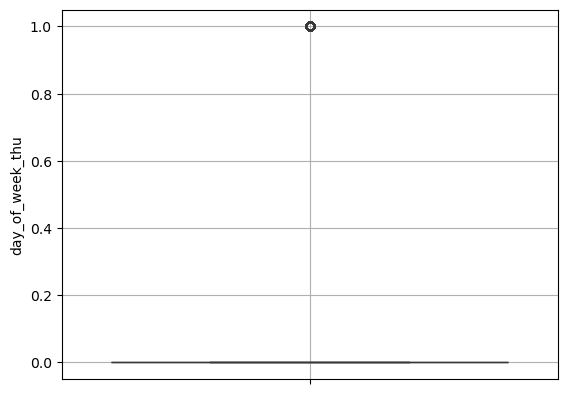

------------------day_of_week_tue------------------



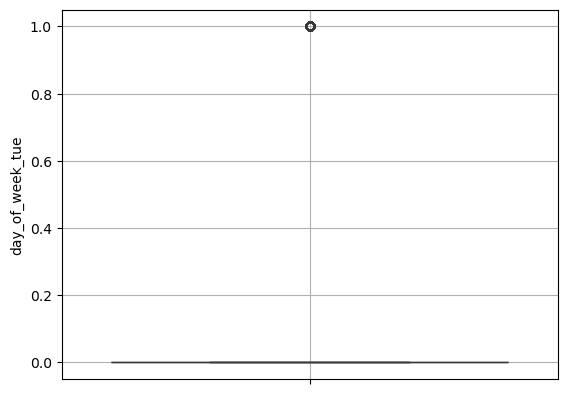

------------------day_of_week_wed------------------



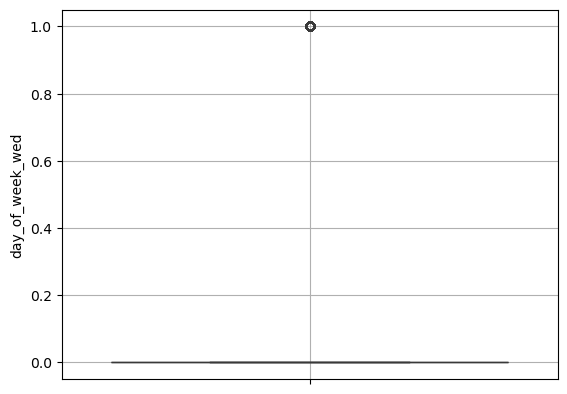

------------------poutcome_failure------------------



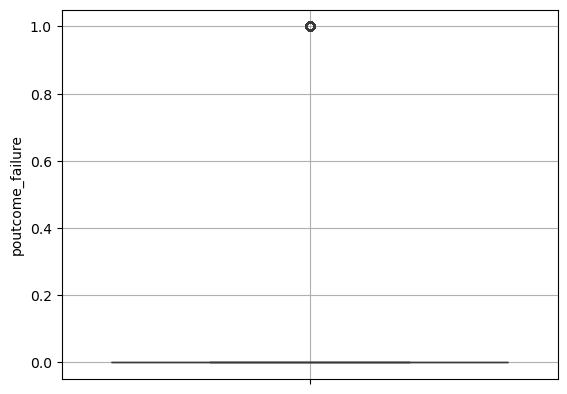

------------------poutcome_nonexistent------------------



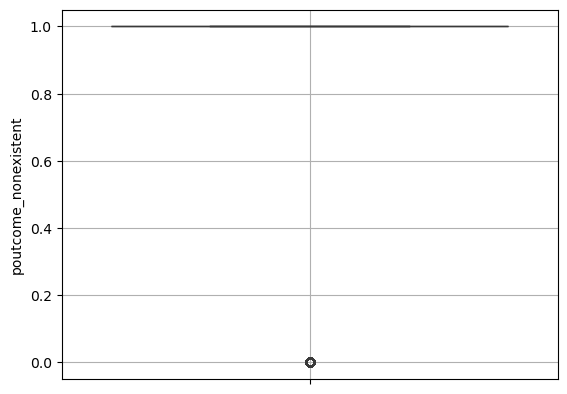

------------------poutcome_success------------------



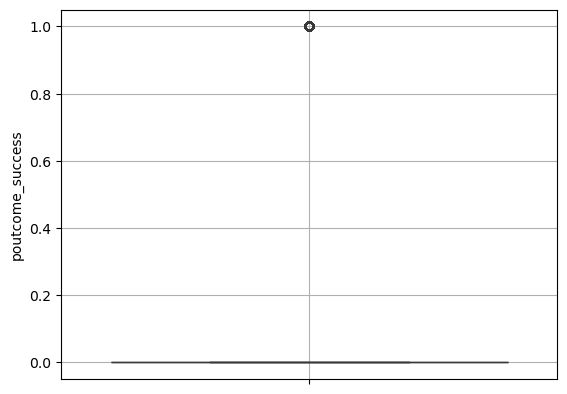

In [38]:
for i in df.columns:
    if i == 'Loan_Status_label':
        pass
    else:
        print(f'------------------{i}------------------\n')
        sns.boxplot(df[i], color='m')
        plt.grid()
        plt.show()

## Feature Selection

In [40]:
df.corr()

,age,campaign,pdays,previous,no_previous_contact,not_working,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success,Loan_Status_label
age,1.000000,-0.000792,-0.032680,0.020430,-0.032600,0.207835,-0.095507,-0.030068,0.027431,0.084198,...,0.040026,0.006287,0.017340,-0.019094,0.017902,-0.022350,-0.007085,-0.011749,0.034118,0.026865
campaign,-0.000792,1.000000,0.057855,-0.086774,0.057840,-0.021846,0.015630,0.000038,-0.004086,0.002921,...,-0.036927,0.025805,0.010532,0.007932,-0.024070,-0.020438,-0.075279,0.096142,-0.055900,-0.074539
pdays,-0.032680,0.057855,1.000000,-0.588940,0.999992,-0.112069,-0.028564,0.066963,0.020523,-0.000918,...,-0.154564,0.014940,0.002517,-0.009324,-0.008213,0.000339,0.009098,0.493971,-0.950559,-0.324611
previous,0.020430,-0.086774,-0.588940,1.000000,-0.588887,0.103602,0.023149,-0.056865,-0.015668,-0.012511,...,0.157224,0.003027,-0.004078,0.002367,0.001799,-0.003039,0.678092,-0.877385,0.525045,0.228665
no_previous_contact,-0.032600,0.057840,0.999992,-0.588887,1.000000,-0.112069,-0.028578,0.066956,0.020524,-0.000907,...,-0.154550,0.014932,0.002493,-0.009325,-0.008194,0.000353,0.008844,0.493975,-0.950141,-0.324572
not_working,0.207835,-0.021846,-0.112069,0.103602,-0.112069,1.000000,-0.181604,-0.169473,-0.061192,-0.051962,...,0.084659,0.001643,-0.006026,-0.001012,0.007139,-0.001549,0.031470,-0.082430,0.103344,0.118294
job_admin.,-0.095507,0.015630,-0.028564,0.023149,-0.028578,-0.181604,1.000000,-0.308601,-0.111427,-0.094620,...,0.011884,0.007820,-0.000429,-0.003825,-0.000034,-0.003369,0.005870,-0.020046,0.028119,0.035250
job_blue-collar,-0.030068,0.000038,0.066963,-0.056865,0.066956,-0.169473,-0.308601,1.000000,-0.103984,-0.088300,...,-0.055378,0.002939,-0.009880,-0.007824,-0.004312,0.019503,-0.014362,0.045937,-0.062914,-0.075625
job_entrepreneur,0.027431,-0.004086,0.020523,-0.015668,0.020524,-0.061192,-0.111427,-0.103984,1.000000,-0.031882,...,-0.009700,-0.000656,0.005297,0.004588,-0.005552,-0.003921,-0.000734,0.010381,-0.018425,-0.019306
job_housemaid,0.084198,0.002921,-0.000918,-0.012511,-0.000907,-0.051962,-0.094620,-0.088300,-0.031882,1.000000,...,-0.003855,-0.007712,0.002484,-0.009665,0.013182,0.001816,-0.018584,0.015602,0.001598,-0.007496


<Axes: >

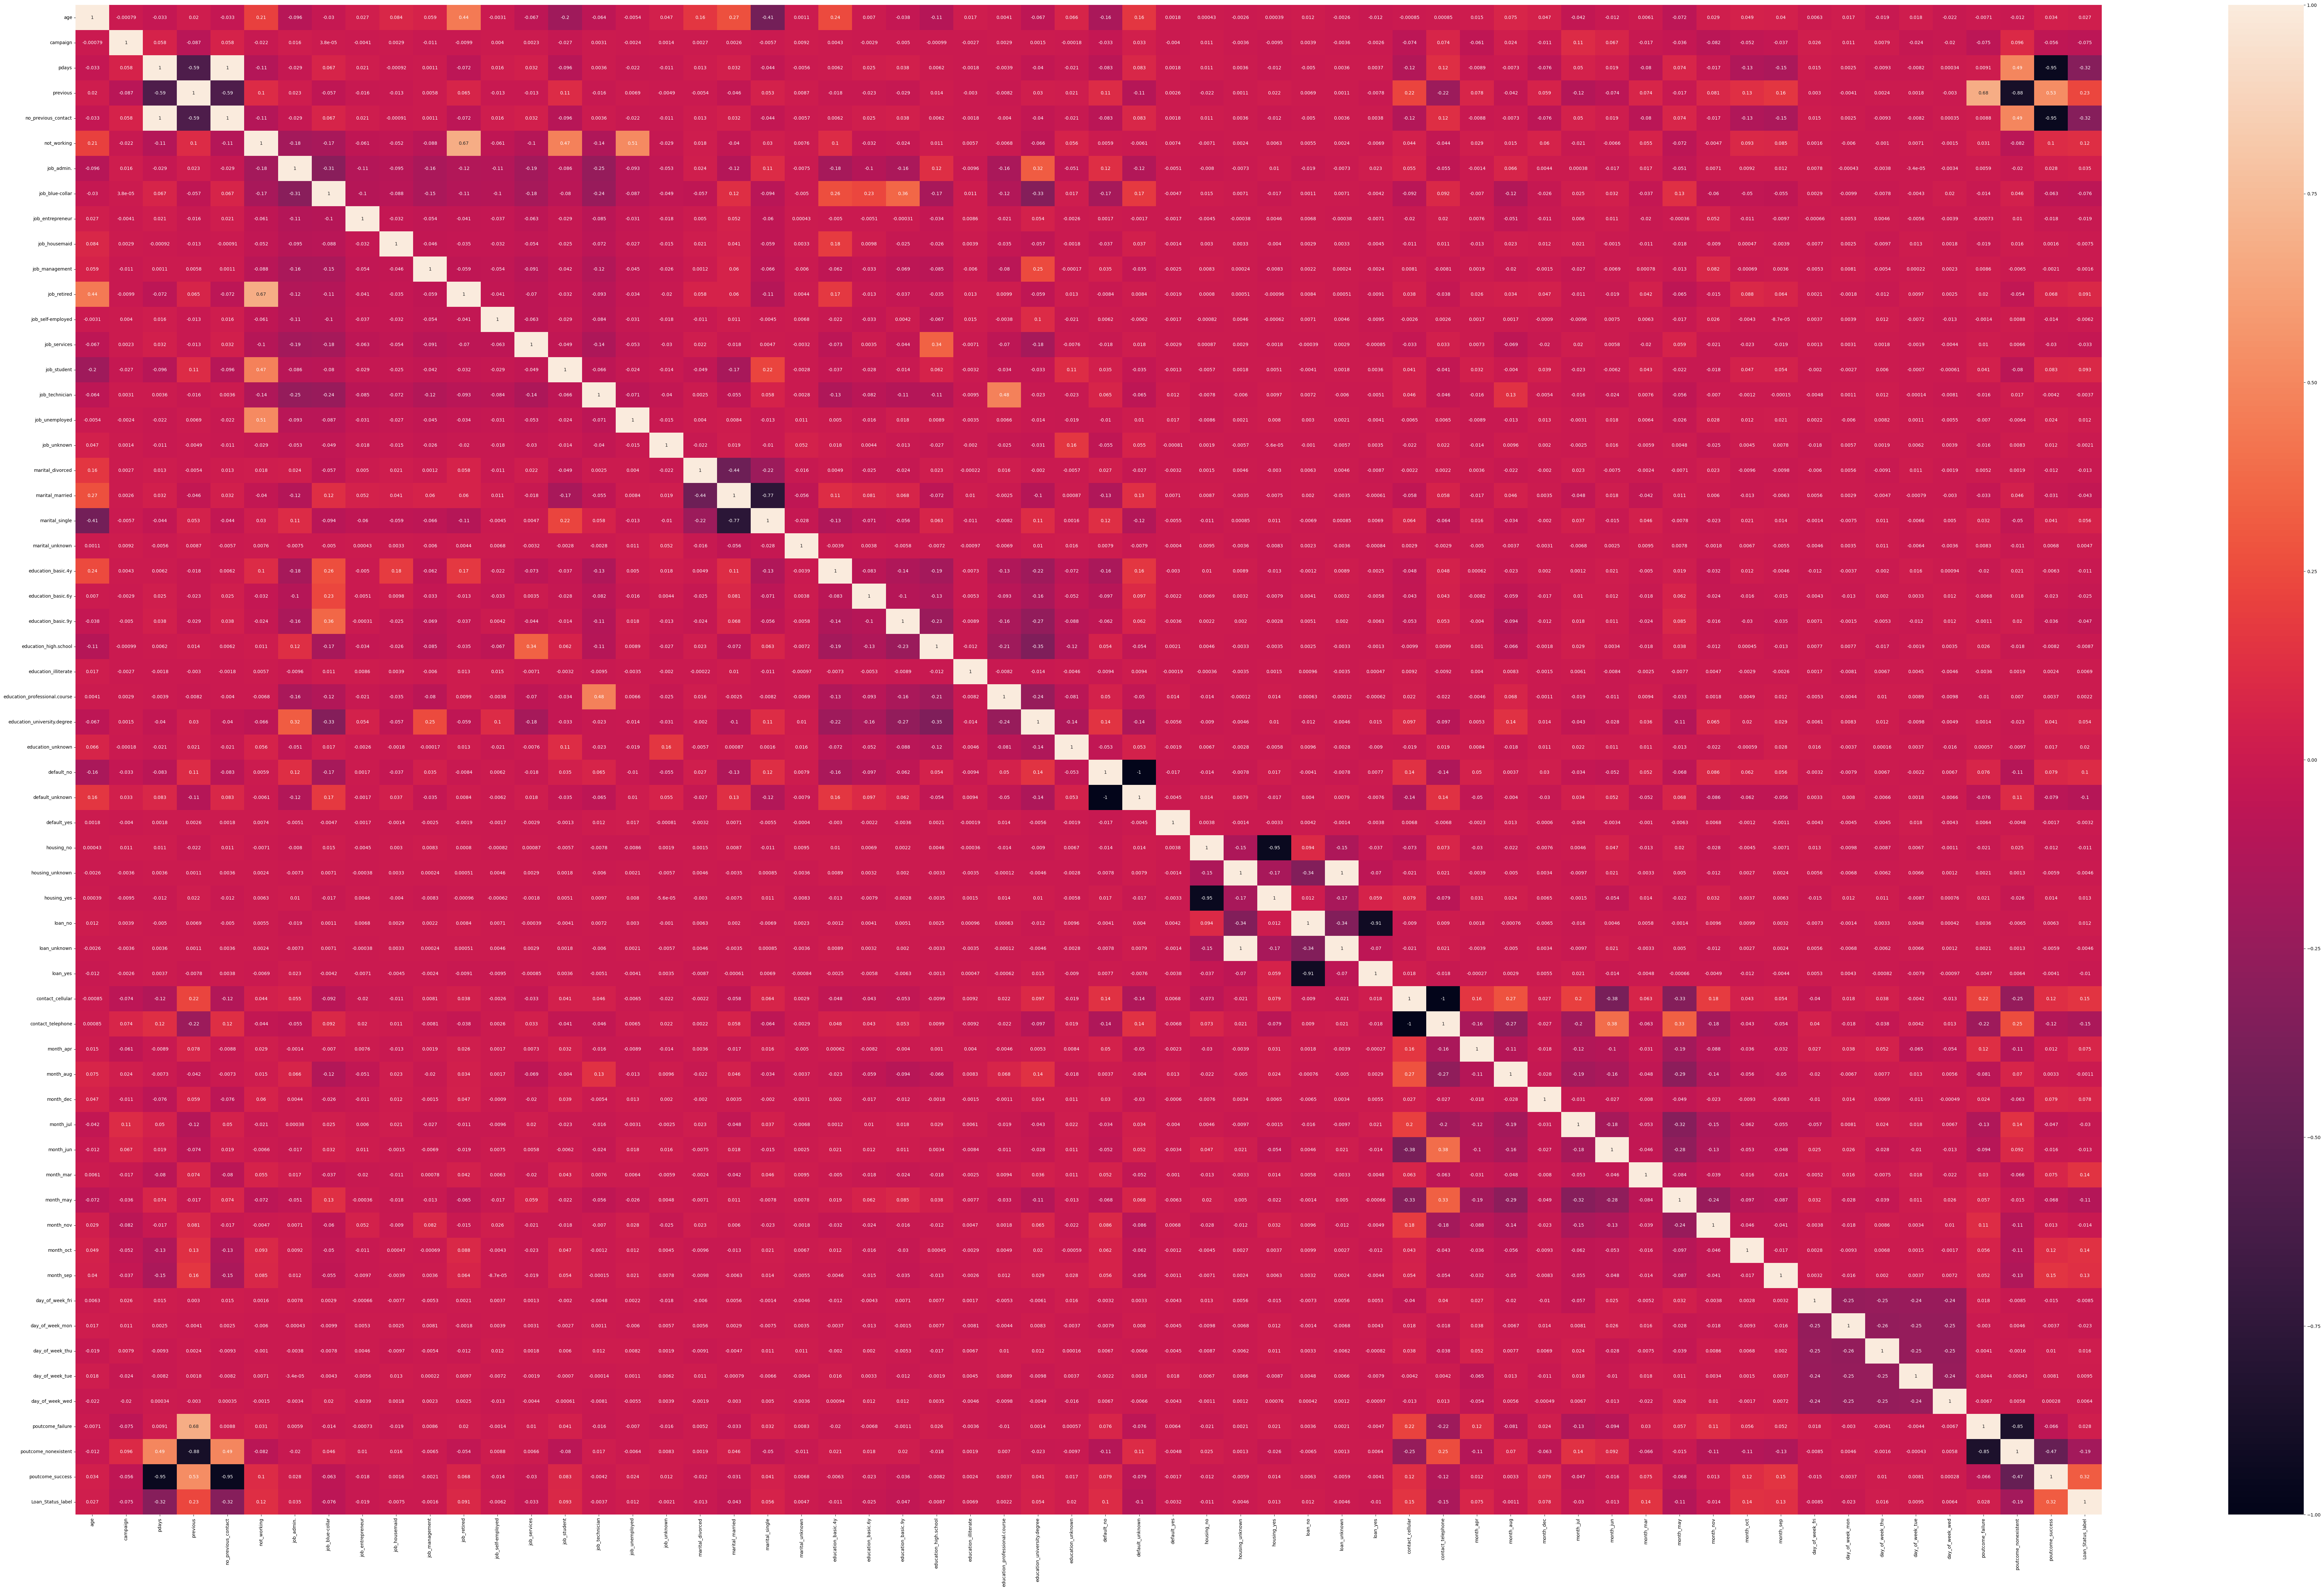

In [42]:
plt.figure(figsize=(100,60))
sns.heatmap(df.corr(), annot=True)

In [44]:
df.corr()['Loan_Status_label']

age                              0.026865
campaign                        -0.074539
pdays                           -0.324611
previous                         0.228665
no_previous_contact             -0.324572
not_working                      0.118294
job_admin.                       0.035250
job_blue-collar                 -0.075625
job_entrepreneur                -0.019306
job_housemaid                   -0.007496
job_management                  -0.001627
job_retired                      0.091108
job_self-employed               -0.006224
job_services                    -0.033042
job_student                      0.092536
job_technician                  -0.003678
job_unemployed                   0.012016
job_unknown                     -0.002082
marital_divorced                -0.013390
marital_married                 -0.043307
marital_single                   0.056264
marital_unknown                  0.004679
education_basic.4y              -0.011243
education_basic.6y              -0

# Model Building

In [48]:
X = df.drop(columns=['Loan_Status_label'], axis=1)
y = df['Loan_Status_label']

In [50]:
X

,age,campaign,pdays,previous,no_previous_contact,not_working,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_oct,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success
0,56,1,999,0,1,0,0,0,0,1,...,0,0,0,1,0,0,0,0,1,0
1,57,1,999,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
2,37,1,999,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
3,40,1,999,0,1,0,1,0,0,0,...,0,0,0,1,0,0,0,0,1,0
4,56,1,999,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,1,999,0,1,1,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
41184,46,1,999,0,1,0,0,1,0,0,...,0,0,1,0,0,0,0,0,1,0
41185,56,2,999,0,1,1,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
41186,44,1,999,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0


In [52]:
y

0        0
1        0
2        0
3        0
4        0
        ..
41183    1
41184    0
41185    0
41186    1
41187    0
Name: Loan_Status_label, Length: 38771, dtype: int64

## Balancing Imbalance Data

In [66]:
from sklearn.utils import resample

X_minority = X[y == 1]
X_majority = X[y == 0]
y_minority = y[y == 1]
y_majority = y[y == 0]

X_majority_downsampled, y_majority_downsampled = resample(X_majority, y_majority, 
                                                         replace=False,  
                                                         n_samples=len(X_minority), 
                                                         random_state=42)

X_resampled = np.vstack((X_majority_downsampled, X_minority))
y_resampled = np.hstack((y_majority_downsampled, y_minority))

In [68]:
X_resampled, _, y_resampled, _ = train_test_split(X, y, 
                                                 train_size=2*len(y[y == 1]), 
                                                 stratify=y, 
                                                 random_state=42)

In [70]:
X_resampled

,age,campaign,pdays,previous,no_previous_contact,not_working,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_oct,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success
2405,40,1,999,0,1,0,0,1,0,0,...,0,0,0,0,0,1,0,0,1,0
23236,47,3,999,0,1,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
8951,60,2,999,0,1,1,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
12333,41,1,999,0,1,0,0,1,0,0,...,0,0,1,0,0,0,0,0,1,0
28517,45,4,999,0,1,0,0,1,0,0,...,0,0,0,0,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
751,36,3,999,0,1,0,0,1,0,0,...,0,0,0,0,0,1,0,0,1,0
6020,31,3,999,0,1,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
30151,46,1,999,0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
7123,47,1,999,0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0


In [72]:
y_resampled

2405     0
23236    0
8951     0
12333    0
28517    0
        ..
751      0
6020     0
30151    0
7123     0
37733    0
Name: Loan_Status_label, Length: 9184, dtype: int64

# Split your data into train and test

In [91]:
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

In [93]:
X_train

,age,campaign,pdays,previous,no_previous_contact,not_working,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_oct,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success
14803,49,1,999,0,1,1,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
10104,54,1,999,0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
5741,42,1,999,0,1,0,0,1,0,0,...,0,0,0,1,0,0,0,0,1,0
27195,57,1,999,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
25287,32,1,999,1,1,0,1,0,0,0,...,0,0,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36170,45,5,999,0,1,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
3403,35,4,999,0,1,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
24627,46,2,999,1,1,0,0,1,0,0,...,0,0,0,1,0,0,0,1,0,0
5014,40,12,999,0,1,0,1,0,0,0,...,0,0,0,0,0,0,1,0,1,0


In [96]:
y_train

14803    1
10104    0
5741     0
27195    0
25287    0
        ..
36170    0
3403     0
24627    0
5014     0
33547    0
Name: Loan_Status_label, Length: 7347, dtype: int64

In [98]:
X_test

,age,campaign,pdays,previous,no_previous_contact,not_working,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_oct,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success
32606,42,5,999,2,1,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0
21221,48,1,999,0,1,0,0,1,0,0,...,0,0,0,1,0,0,0,0,1,0
7473,60,2,999,0,1,0,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
20985,59,1,999,0,1,1,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
17066,49,2,999,0,1,0,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33298,51,1,999,1,1,0,0,1,0,0,...,0,0,0,0,0,1,0,1,0,0
40376,27,1,0,5,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1
34148,27,2,999,0,1,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
31973,43,5,999,0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0


In [100]:
y_test

32606    0
21221    0
7473     0
20985    0
17066    0
        ..
33298    0
40376    0
34148    0
31973    0
4664     0
Name: Loan_Status_label, Length: 1837, dtype: int64

# Feature Scaling

In [113]:
from sklearn.preprocessing import StandardScaler

In [115]:
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.fit_transform(X_test)

In [117]:
X_train_sc

array([[ 0.86032418, -0.59124174,  0.20596782, ..., -0.34735117,
         0.4108379 , -0.19532475],
       [ 1.34481045, -0.59124174,  0.20596782, ..., -0.34735117,
         0.4108379 , -0.19532475],
       [ 0.18204339, -0.59124174,  0.20596782, ..., -0.34735117,
         0.4108379 , -0.19532475],
       ...,
       [ 0.56963241, -0.23099518,  0.20596782, ...,  2.87893083,
        -2.43405001, -0.19532475],
       [-0.01175112,  3.37147048,  0.20596782, ..., -0.34735117,
         0.4108379 , -0.19532475],
       [-0.6900319 , -0.23099518,  0.20596782, ..., -0.34735117,
         0.4108379 , -0.19532475]])

In [119]:
X_test_sc

array([[ 0.20761785,  0.90441322,  0.19755088, ...,  2.91016703,
        -2.51952376, -0.17732177],
       [ 0.77985188, -0.57733223,  0.19755088, ..., -0.34362289,
         0.3969004 , -0.17732177],
       [ 1.92431995, -0.20689587,  0.19755088, ..., -0.34362289,
         0.3969004 , -0.17732177],
       ...,
       [-1.22296724, -0.20689587,  0.19755088, ..., -0.34362289,
         0.3969004 , -0.17732177],
       [ 0.30299018,  0.90441322,  0.19755088, ..., -0.34362289,
         0.3969004 , -0.17732177],
       [-1.31833958, -0.57733223,  0.19755088, ..., -0.34362289,
         0.3969004 , -0.17732177]])

# Model Selection

## Logistic Regression

In [123]:
lr = LogisticRegression()
lr.fit(X_train_sc, y_train)

LogisticRegression()

In [125]:
print(f'Training Accuracy : {round(lr.score(X_train_sc, y_train), 2)*100} %')
print(f'Test Accuracy : {round(lr.score(X_test_sc, y_test), 2)*100} %')

Training Accuracy : 89.0 %
Test Accuracy : 89.0 %


## Decision Tree

In [162]:
dtree = DecisionTreeClassifier(max_depth=4)
dtree.fit(X_train_sc, y_train)

DecisionTreeClassifier(max_depth=4)

In [164]:
print(f'Training Accuracy : {round(dtree.score(X_train_sc, y_train), 2)*100} %')
print(f'Test Accuracy : {round(dtree.score(X_test_sc, y_test), 2)*100} %')

Training Accuracy : 90.0 %
Test Accuracy : 89.0 %


## Gradient Boosting

In [200]:
gb = GradientBoostingClassifier(max_depth=5)
gb.fit(X_train_sc, y_train)

GradientBoostingClassifier(max_depth=5)

In [202]:
print(f'Training Accuracy : {round(gb.score(X_train_sc, y_train), 2)*100} %')
print(f'Test Accuracy : {round(gb.score(X_test_sc, y_test), 2)*100} %')

Training Accuracy : 92.0 %
Test Accuracy : 88.0 %


## Random Forest Classifier

In [220]:
rf = RandomForestClassifier(max_depth=4)
rf.fit(X_train_sc, y_train)

RandomForestClassifier(max_depth=4)

In [222]:
print(f'Training Accuracy : {round(rf.score(X_train_sc, y_train), 2)*100} %')
print(f'Test Accuracy : {round(rf.score(X_test_sc, y_test), 2)*100} %')

Training Accuracy : 90.0 %
Test Accuracy : 89.0 %


# Model Training - Gradient Boosting

In [268]:
gb = GradientBoostingClassifier()
gb.fit(X_train_sc, y_train)

GradientBoostingClassifier()

# Model Prediction

In [270]:
y_pred_train = gb.predict(X_train_sc)
y_pred_test = gb.predict(X_test_sc)

# Model Evaluation

In [272]:
# Training Data

confusion_matrix(y_train, y_pred_train)

array([[6419,   55],
       [ 659,  214]], dtype=int64)

<Axes: >

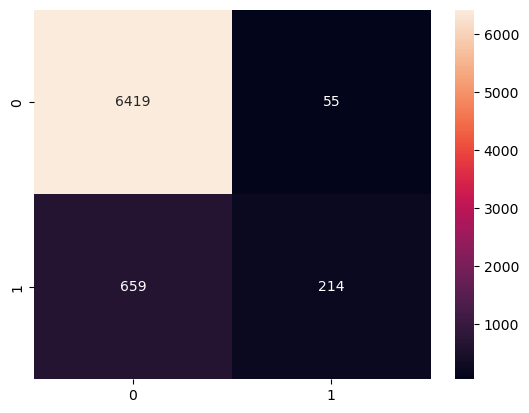

In [274]:
sns.heatmap(confusion_matrix(y_train, y_pred_train), annot=True, fmt='.4g')

In [276]:
accuracy_score(y_train, y_pred_train)

0.902817476521029

In [278]:
print(classification_report(y_train, y_pred_train))

              precision    recall  f1-score   support

           0       0.91      0.99      0.95      6474
           1       0.80      0.25      0.37       873

    accuracy                           0.90      7347
   macro avg       0.85      0.62      0.66      7347
weighted avg       0.89      0.90      0.88      7347



In [280]:
# Test Data

confusion_matrix(y_test, y_pred_test)

array([[1590,   32],
       [ 177,   38]], dtype=int64)

<Axes: >

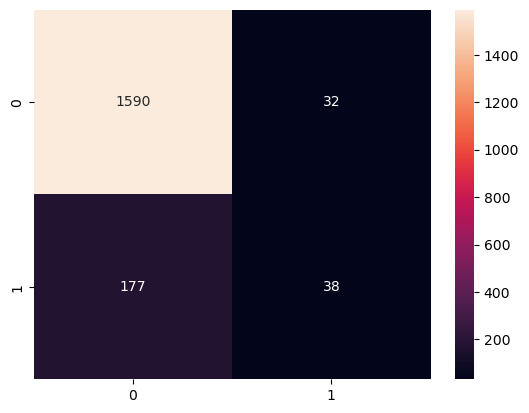

In [282]:
sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt='.4g')

In [284]:
accuracy_score(y_test, y_pred_test)

0.8862275449101796

In [286]:
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.90      0.98      0.94      1622
           1       0.54      0.18      0.27       215

    accuracy                           0.89      1837
   macro avg       0.72      0.58      0.60      1837
weighted avg       0.86      0.89      0.86      1837

